# IPCV Practicals — Crash Revision Notebook
**Python • OpenCV • NumPy • Matplotlib**

Run each question's code cell separately in Jupyter Notebook, JupyterLab, VS Code, or Google Colab. Place the required images/videos in the notebook's working folder, or change filenames to match your files.

**Setup:** Run the next cell once before starting.

In [ ]:
# Install dependencies in your local terminal if needed:
# pip install opencv-python numpy matplotlib
import cv2
import numpy as np
import matplotlib.pyplot as plt

# For local use, place the required image/video files in the same folder as this notebook.
# In Jupyter, use the file upload button in your notebook environment if available.

## 1. Generate all possible images for a 3 × 2 black-and-white camera

Six pixels, each either black (0) or white (255), give \(2^6 = 64\) possible images.

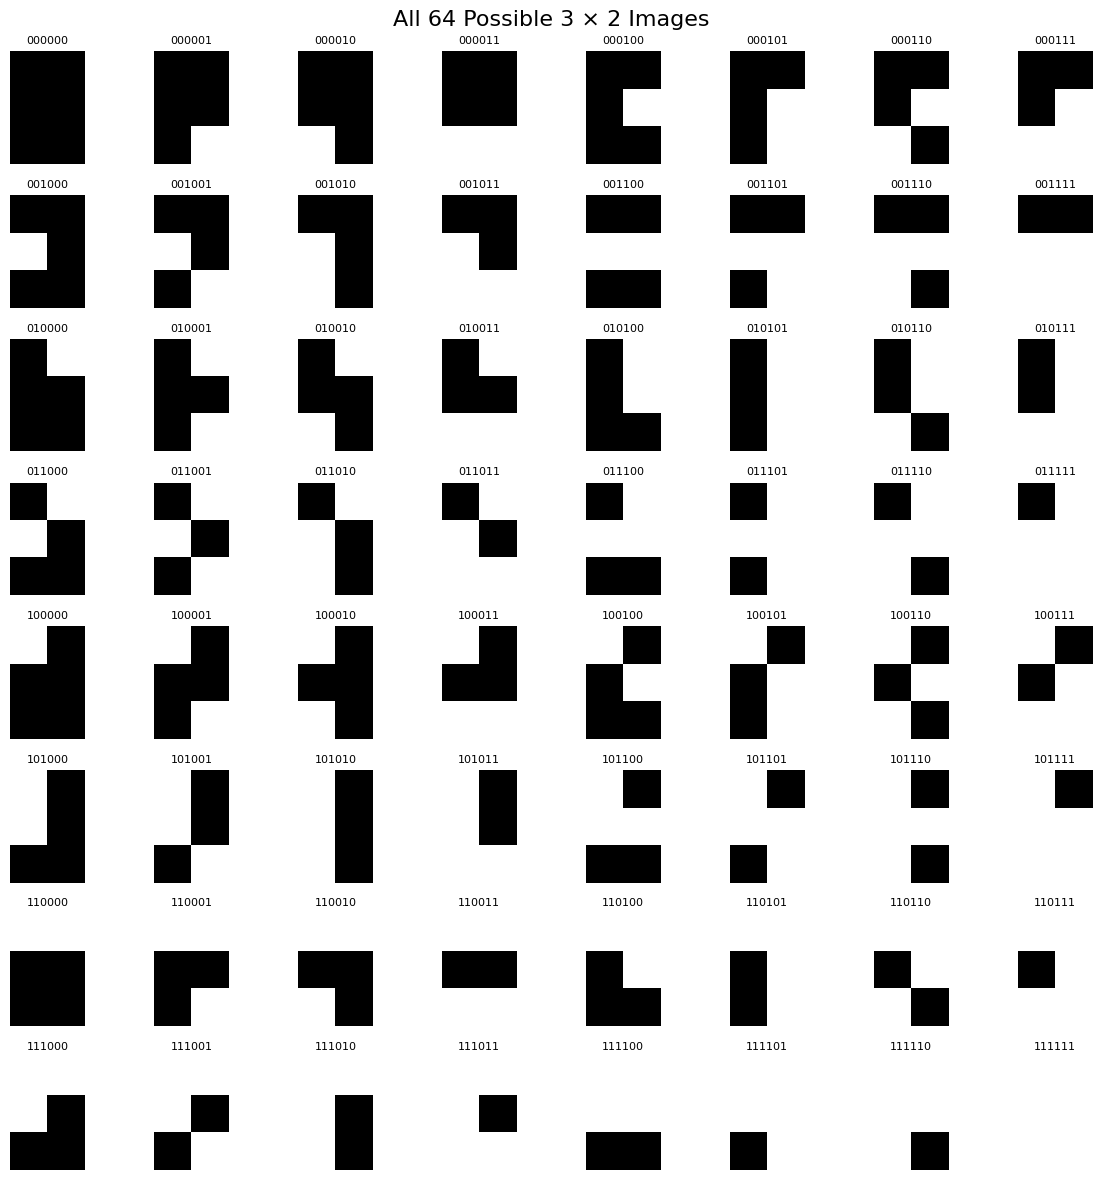

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(8, 8, figsize=(12, 12))
fig.suptitle("All 64 Possible 3 × 2 Images", fontsize=16)

for i, ax in enumerate(axes.flat):
    ax.imshow(np.array(list(f"{i:06b}"), int).reshape(3, 2), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{i:06b}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Randomly fill a 3 × 3 binary image until it looks sensible

A 3 × 3 image has only nine pixels, so the possible pictures are very limited.

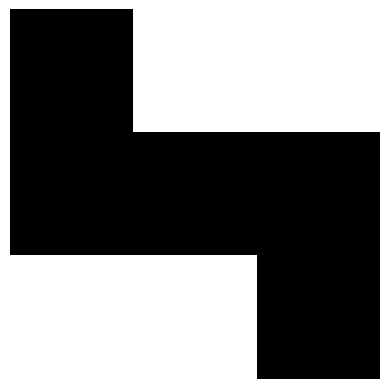

Sensible image? (y/n): n


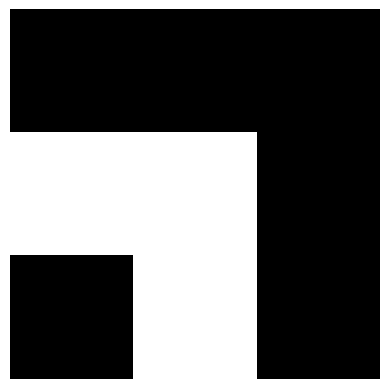

Sensible image? (y/n): 


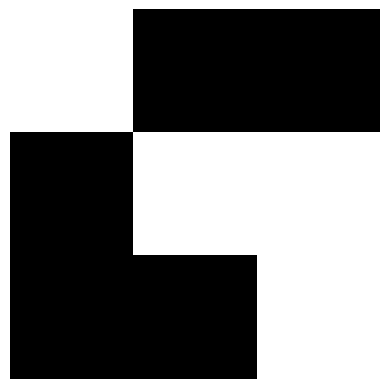

Sensible image? (y/n): n


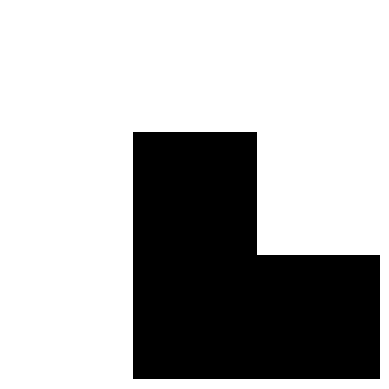

Sensible image? (y/n): y


In [ ]:
while True:
    img = np.random.choice([0, 255], (3, 3))
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.axis('off')
    plt.show()
    if input("Sensible image? (y/n): ").lower() == 'y':
        break

## 3. Draw five 5 × 5 binary characters in your mother tongue

These are **illustrative pixel patterns**, not accurate Tamil glyphs. Replace them with five characters/patterns you can identify and label correctly for your mother tongue.

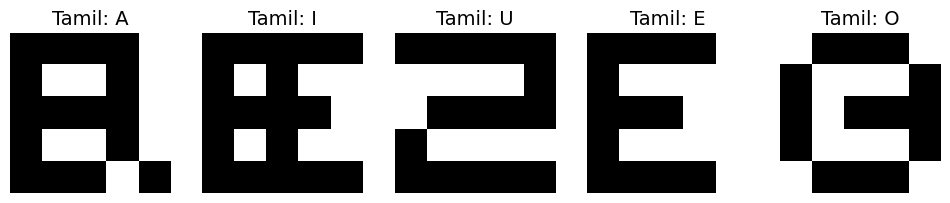

In [ ]:
# 5x5 binary approximations of Tamil vowel characters: அ (A), இ (I), உ (U), எ (E), ஒ (O)
tamil_chars = [
    # அ (A)
    [[1,0,0,0,1],
     [1,0,0,0,1],
     [1,0,0,0,1],
     [1,0,0,0,1],
     [1,1,1,1,1]],

    # இ (I)
    # [[1,1,1,1,1],
    #  [1,0,1,0,0],
    #  [1,1,1,1,0],
    #  [1,0,1,0,0],
    #  [1,1,1,1,1]],

    # # உ (U)
    # [[1,1,1,1,1],
    #  [0,0,0,0,1],
    #  [0,1,1,1,1],
    #  [1,0,0,0,0],
    #  [1,1,1,1,1]],

    # # எ (E)
    # [[1,1,1,1,0],
    #  [1,0,0,0,0],
    #  [1,1,1,0,0],
    #  [1,0,0,0,0],
    #  [1,1,1,1,0]],

    # # ஒ (O)
    # [[0,1,1,1,0],
    #  [1,0,0,0,1],
    #  [1,0,1,1,1],
    #  [1,0,0,0,1],
    #  [0,1,1,1,0]]
]

# Using English phonetic labels to prevent font rendering warnings in Matplotlib
labels = ['Tamil: A', 'Tamil: I', 'Tamil: U', 'Tamil: E', 'Tamil: O']

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(tamil_chars[i], cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(labels[i], fontsize=14)
    ax.axis('off')
plt.show()

## 4. Coin area percentage versus camera distance

Place ten coin images named `coin1.jpg` ... `coin10.jpg` in the notebook's working folder, and enter the measured distances in cm. This assumes the coin is darker than its background; inspect the threshold mask and adjust if needed.

In [ ]:
# Place coin1.jpg ... coin10.jpg in this notebook's working folder.
distances = list(map(float, input("Enter 10 distances in cm, comma-separated: ").split(',')))
percentages = []

for i in range(1, 11):
    img = cv2.imread(f'coin{i}.jpg', cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read coin{i}.jpg")
    _, mask = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    percentages.append(np.count_nonzero(mask) / mask.size * 100)

plt.plot(distances, percentages, 'o-')
plt.xlabel('Capturing distance (cm)')
plt.ylabel('Coin area (% of image)')
plt.grid(True)
plt.show()
print("Area percentages:", percentages)

## 5. Read an image matrix and extract neighbourhoods

The 8-neighbourhood is the surrounding 3 × 3 patch excluding its centre. A common 16-neighbourhood is defined as a ring of 16 surrounding pixels in a 5 × 5 patch; the exact convention may depend on your lab notes.

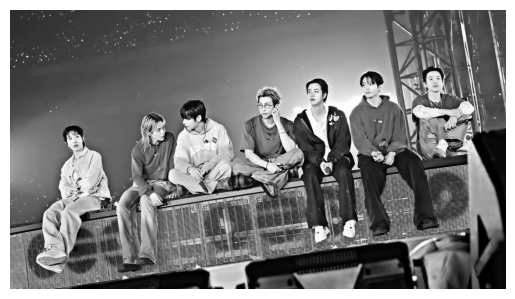

Image shape: (736, 1308)
Centre pixel: 52
8-neighbours:
 [[47 55 67]
 [45 52 61]
 [42 46 53]]
16 neighbours: [42, 47, 56, 68, 80, 80, 81, 73, 37, 39, 39, 44, 63, 42, 37, 37]


In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("image.jpg", 0)

if img is None:
    raise FileNotFoundError("Image not found")

plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

r, c = img.shape[0] // 2, img.shape[1] // 2

print("Image shape:", img.shape)
print("Centre pixel:", img[r, c])
print("8-neighbours:\n", img[r-1:r+2, c-1:c+2])

patch = img[r-2:r+3, c-2:c+3]
ring16 = (patch[0, :].tolist() + patch[1:4, 4].tolist()
          + patch[4, :].tolist() + patch[1:4, 0].tolist())

print("16 neighbours:", ring16)


## 6. Generate the negative of a square image

For an 8-bit image, the negative transformation is `s = 255 - r`.

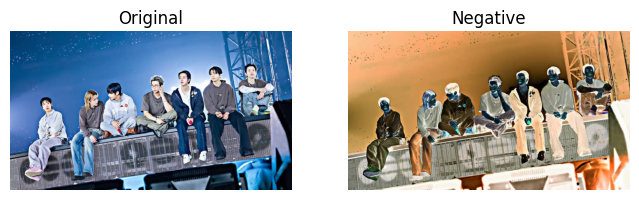

In [ ]:
img = cv2.imread('image.jpg')  # Upload square.jpg
if img is None:
    raise FileNotFoundError("Upload square.jpg")
negative = 255 - img

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1);
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB));
plt.title('Original');
plt.axis('off')

plt.subplot(1, 2, 2);
plt.imshow(cv2.cvtColor(negative, cv2.COLOR_BGR2RGB));
plt.title('Negative');
plt.axis('off')

plt.show()

## 7. Capture parallel notebook lines at different perspective angles

Capture and upload images named `lines1.jpg`, `lines2.jpg`, and `lines3.jpg`. This code displays them for comparison; record how line orientation and spacing appear to change.

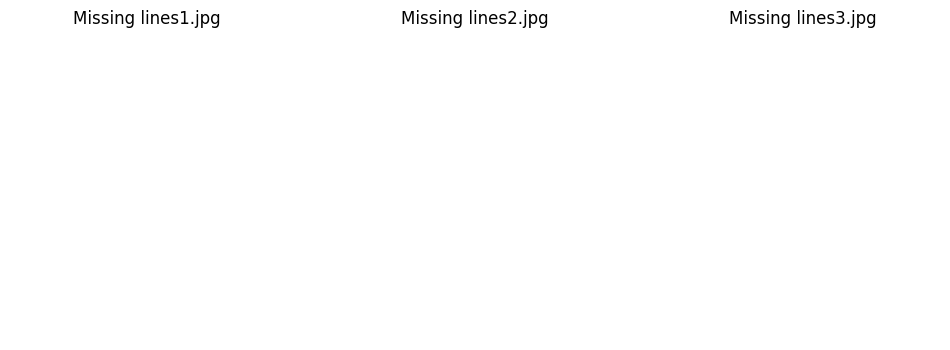

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, ax in enumerate(axes, 1):
    img = cv2.imread(f'lines{i}.jpg')
    if img is None:
        ax.set_title(f'Missing lines{i}.jpg')
        ax.axis('off')
        continue
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f'Angle {i}')
    ax.axis('off')
plt.show()

## 8. Apply power-law (gamma) transformations to a selfie

Formula: \(s = c r^\gamma\). With normalized intensities and `c = 1`, gamma below 1 brightens; gamma above 1 darkens.

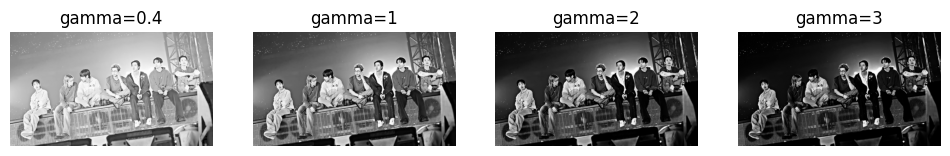

In [ ]:
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)  # Upload selfie.jpg
if img is None:
    raise FileNotFoundError("Upload selfie.jpg")
fig, axes = plt.subplots(1, 4, figsize=(12, 4))
for ax, gamma in zip(axes, [0.4, 1, 2, 3]):
    out = np.uint8(255 * (img / 255.0) ** gamma)
    ax.imshow(out, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'gamma={gamma}')
    ax.axis('off')
plt.show()

## 9. Convolve an image of repeated same-size shapes

Use a Laplacian kernel to emphasize intensity changes/edges. Upload `shapes.jpg`. For a strict from-scratch convolution requirement, implement the sliding window manually instead of using `filter2D`.

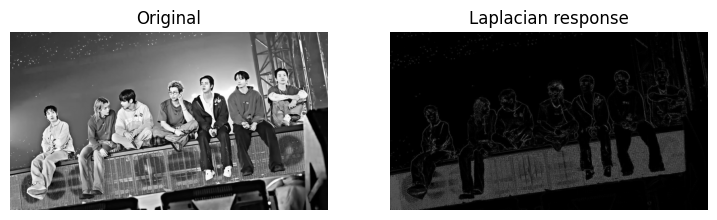

In [ ]:
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Upload shapes.jpg")
kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
out = cv2.filter2D(img, cv2.CV_32F, kernel)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(img, cmap='gray');
axes[0].set_title('Original')

axes[1].imshow(np.abs(out), cmap='gray');
axes[1].set_title('Laplacian response')

for ax in axes: ax.axis('off')
plt.show()

## 10. Add Gaussian noise and recover with a 5 × 5 averaging filter; calculate MSE

The question specifies noise with mean 110 and standard deviation 5. Adding it directly creates a strong positive brightness shift, so the averaging filter will not remove the bias completely.

MSE: 10927.579


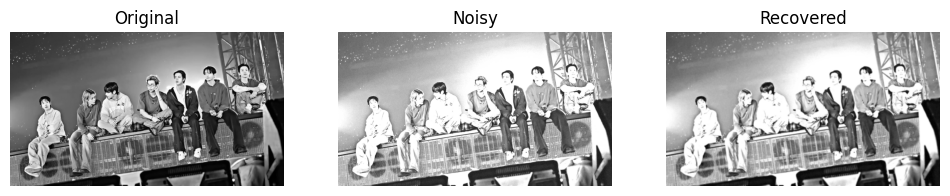

In [ ]:
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Upload selfie.jpg")
original = img.astype(np.float32)
noise = np.random.normal(110, 5, original.shape)
noisy = np.clip(original + noise, 0, 255).astype(np.uint8)
recovered = cv2.blur(noisy, (5, 5))
mse = np.mean((original - recovered.astype(np.float32)) ** 2)
print("MSE:", mse)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, title in zip(axes, [img, noisy, recovered], ['Original', 'Noisy', 'Recovered']):
    ax.imshow(im, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.show()

## 11. Rotate, scale, and shear using explicit operator matrices

This uses homogeneous transformation matrices and inverse mapping with nearest-neighbour sampling. It does not call ready-made rotate, resize, or shear functions. It may be slow for large selfies; resize the input first if needed.

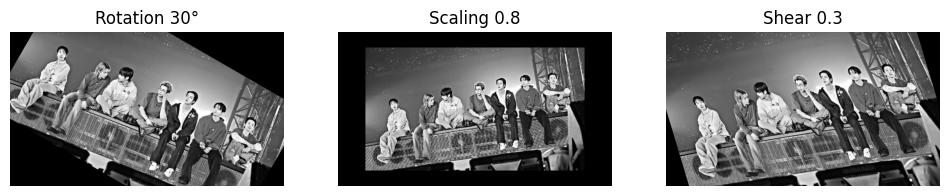

Challenges: clipping, holes, interpolation artefacts, and loss of detail.


In [ ]:
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Upload selfie.jpg")
h, w = img.shape
cx, cy = w // 2, h // 2
T = np.array([[1, 0, cx], [0, 1, cy], [0, 0, 1]], dtype=float)
Ti = np.array([[1, 0, -cx], [0, 1, -cy], [0, 0, 1]], dtype=float)

a = np.radians(30)
R = np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])
S = np.array([[0.8, 0, 0], [0, 0.8, 0], [0, 0, 1]])
H = np.array([[1, 0.3, 0], [0, 1, 0], [0, 0, 1]])

def transform(M):
    out = np.zeros_like(img)
    A = np.linalg.inv(T @ M @ Ti)
    for y in range(h):
        for x in range(w):
            X, Y, _ = A @ [x, y, 1]
            X, Y = round(X), round(Y)
            if 0 <= X < w and 0 <= Y < h:
                out[y, x] = img[Y, X]
    return out

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, M, title in zip(axes, [R, S, H], ['Rotation 30°', 'Scaling 0.8', 'Shear 0.3']):
    ax.imshow(transform(M), cmap='gray'); ax.set_title(title); ax.axis('off')
plt.show()
print("Challenges: clipping, holes, interpolation artefacts, and loss of detail.")

## 12. Track leaf-apex coordinates and apply 1D and 2D FFT

For sampled frames, enter `row column` coordinates for the leaf apex. This manual approach avoids needing a separate tracking algorithm. The 2D FFT is applied to a sampled video frame. Upload `leaf.mp4`.

In [ ]:
cap = cv2.VideoCapture('leaf.mp4')
if not cap.isOpened():
    raise FileNotFoundError("Upload leaf.mp4")
rows, cols = [], []
last_frame = None
i = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    last_frame = frame
    if i % 15 == 0:
        print("Frame", i, "- enter row and column:")
        r, c = map(int, input().split())
        rows.append(r); cols.append(c)
    i += 1
cap.release()

plt.plot(np.abs(np.fft.fft(rows)), label='Row-coordinate FFT')
plt.plot(np.abs(np.fft.fft(cols)), label='Column-coordinate FFT')
plt.legend(); plt.xlabel('Frequency index'); plt.show()

gray = cv2.cvtColor(last_frame, cv2.COLOR_BGR2GRAY)
F = np.fft.fftshift(np.fft.fft2(gray))
plt.imshow(np.log1p(np.abs(F)), cmap='gray')
plt.title('2D FFT magnitude'); plt.axis('off'); plt.show()

## 13. String-art reconstruction and histogram equalization

Place `image.jpg` in the working folder. Compare its histogram with the equalized version, then upload both images separately to the string-art website and compare reconstruction quality.

/tmp/ipykernel_979/1780465155.py:9: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axes[1, 0].hist(img.ravel(), 256, [0, 256]); axes[1, 0].set_title('Original histogram')
/tmp/ipykernel_979/1780465155.py:10: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axes[1, 1].hist(eq.ravel(), 256, [0, 256]); axes[1, 1].set_title('Equalized histogram')


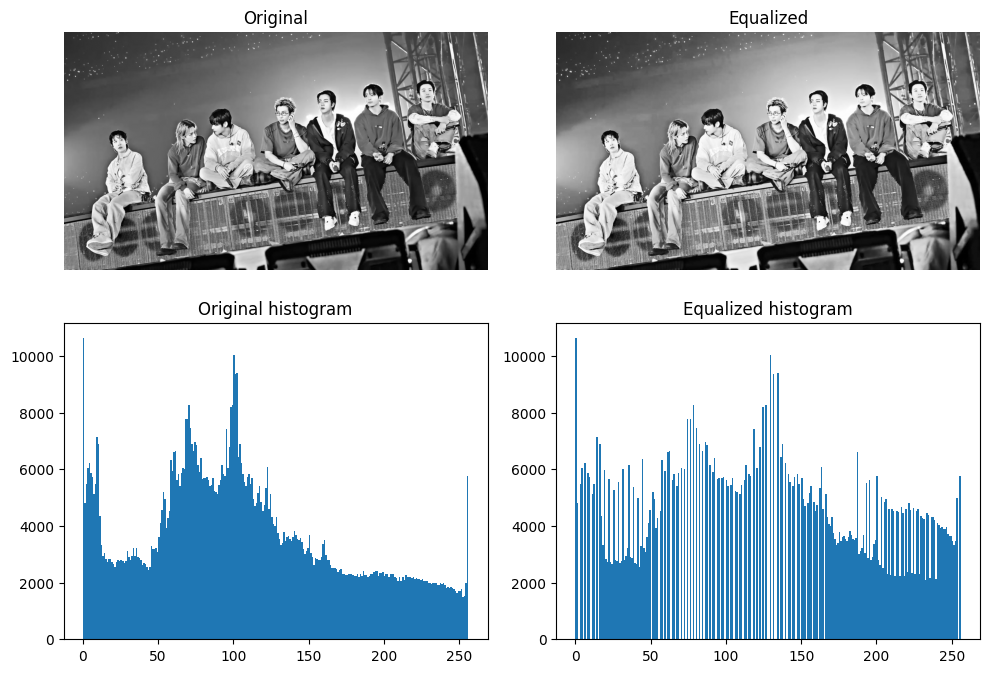

Saved equalized.jpg in the current working folder.


In [ ]:
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Upload image.jpg")
eq = cv2.equalizeHist(img)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].imshow(img, cmap='gray'); axes[0, 0].set_title('Original')
axes[0, 1].imshow(eq, cmap='gray'); axes[0, 1].set_title('Equalized')
axes[1, 0].hist(img.ravel(), 256, [0, 256]); axes[1, 0].set_title('Original histogram')
axes[1, 1].hist(eq.ravel(), 256, [0, 256]); axes[1, 1].set_title('Equalized histogram')
for ax in axes.flat:
    if ax in axes[0]: ax.axis('off')
plt.tight_layout(); plt.show()
cv2.imwrite('equalized.jpg', eq)
print('Saved equalized.jpg in the current working folder.')

## 14. Implement edge detection algorithms

Sobel gradient and Canny edge detection.

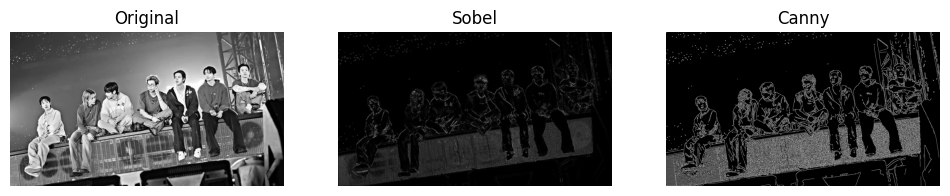

In [ ]:
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
if img is None: raise FileNotFoundError("Upload image.jpg")
sobel = cv2.Sobel(img, cv2.CV_64F, 1, 1, ksize=3)
canny = cv2.Canny(img, 100, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, title in zip(axes, [img, np.abs(sobel), canny], ['Original', 'Sobel', 'Canny']):
    ax.imshow(im, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.show()

## 15. Implement image segmentation

Otsu thresholding automatically chooses a global threshold.

Otsu threshold: 125.0


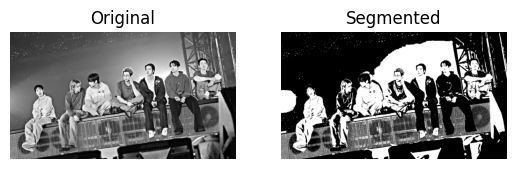

In [ ]:
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
if img is None: raise FileNotFoundError("Upload image.jpg")
t, seg = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold:", t)
plt.subplot(1, 2, 1); plt.imshow(img, cmap='gray'); plt.title('Original'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(seg, cmap='gray'); plt.title('Segmented'); plt.axis('off')
plt.show()

## 16. Implement feature extraction

ORB detects keypoints and computes binary descriptors.

Number of keypoints: 500


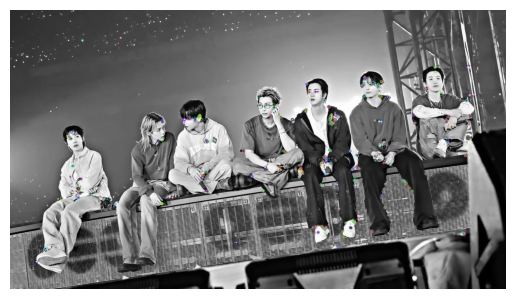

In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Upload image.jpg")

orb = cv2.ORB_create()
kp, des = orb.detectAndCompute(img, None)

out = cv2.drawKeypoints(img, kp, None)

print("Number of keypoints:", len(kp))

plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## 17. Implement object detection

YOLOv11 nano pretrained model. Requires internet access for first-time model-weight download and the `ultralytics` package.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

0: 384x640 7 persons, 1 bench, 335.8ms
Speed: 17.2ms preprocess, 335.8ms inference, 31.6ms postprocess per image at shape (1, 3, 384, 640)


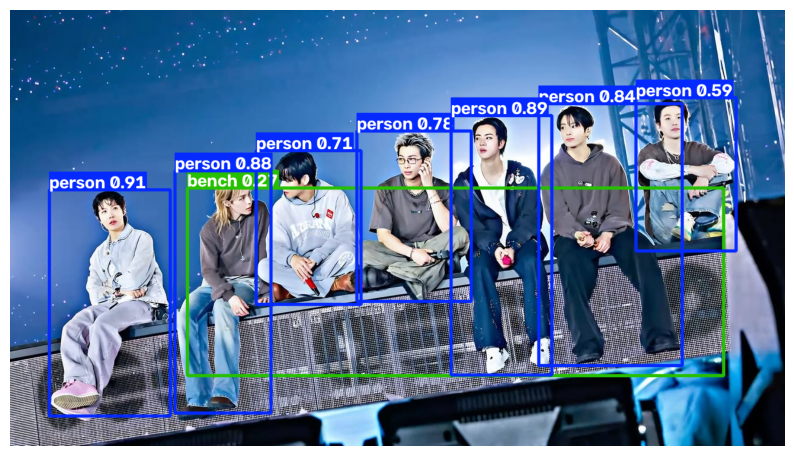

In [ ]:
!pip -q install ultralytics
from ultralytics import YOLO
img = cv2.imread('image.jpg')
if img is None: raise FileNotFoundError("Upload image.jpg")
model = YOLO('yolo11n.pt')
result = model(img)[0]
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
plt.axis('off'); plt.show()

## 18. Object recognition using different deep learning models

Compare ImageNet predictions from MobileNetV2 and ResNet50. Requires TensorFlow and internet access to download pretrained weights.

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.imagenet_utils import decode_predictions

img = tf.keras.utils.load_img('image.jpg', target_size=(224, 224))
x = tf.keras.utils.img_to_array(img)
x = np.expand_dims(x, 0)

for name, model_fn, preprocess in [
    ('MobileNetV2', tf.keras.applications.MobileNetV2, tf.keras.applications.mobilenet_v2.preprocess_input),
    ('ResNet50', tf.keras.applications.ResNet50, tf.keras.applications.resnet50.preprocess_input)
]:
    model = model_fn(weights='imagenet')
    pred = model.predict(preprocess(x.copy()), verbose=0)
    print(name, decode_predictions(pred, top=3)[0])

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 [('n03598930', 'jigsaw_puzzle', np.float32(0.13692115)), ('n04200800', 'shoe_shop', np.float32(0.12976904)), ('n02877765', 'bottlecap', np.float32(0.03511083))]
102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
ResNet50 [('n03598930', 'jigsaw_puzzle', np.float32(0.13183698)), ('n04266014', 'space_shuttle', np.float32(0.06817507)), ('n02071294', 'killer_whale', np.float32(0.058969133))]


## 19. Activity recognition using frame differencing

This detects motion between adjacent video frames. It is a simple motion detector, not a deep-learning action classifier. Upload `activity.mp4`.

In [ ]:
cap = cv2.VideoCapture('activity.mp4')
ok, prev = cap.read()
if not ok: raise FileNotFoundError("Could not read activity.mp4")
prev = cv2.cvtColor(prev, cv2.COLOR_BGR2GRAY)

while True:
    ok, frame = cap.read()
    if not ok: break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    diff = cv2.absdiff(prev, gray)
    _, mask = cv2.threshold(diff, 25, 255, cv2.THRESH_BINARY)
    motion = cv2.countNonZero(mask)
    print('Movement' if motion > 500 else 'Little movement')
    prev = gray
cap.release()

---

## Quick memorization checklist

- **Binary images:** `2**n` possibilities.
- **Negative:** `255 - img`.
- **Gamma:** `(img/255.0)**gamma * 255`.
- **Convolution:** `cv2.filter2D`.
- **Averaging filter:** `cv2.blur(img, (5,5))`.
- **MSE:** `np.mean((original - recovered)**2)`.
- **Histogram equalization:** `cv2.equalizeHist`.
- **Edges:** `cv2.Sobel`, `cv2.Canny`.
- **Segmentation:** `cv2.threshold(..., THRESH_OTSU)`.
- **Features:** `cv2.ORB_create()`.
- **FFT:** `np.fft.fft`, `np.fft.fft2`.
- **Remember:** use the exact input filenames you upload, and run cells separately.